In [1]:
# Langkah 2: Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import os

In [2]:
# Langkah 3: Baca Data
data_path = 'dataset.csv' if os.path.exists('dataset.csv') else ('Jobsheet6_Regresi/dataset.csv' if os.path.exists('Jobsheet6_Regresi/dataset.csv') else 'dataset.csv')
data = pd.read_csv(data_path)
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [3]:
# Langkah 4: Pemahaman Terhadap Data
print("Ukuran data:", data.shape)
print("\nInformasi data:")
data.info()
print("\nDeskripsi statistik data:")
data.describe()

Ukuran data: (500, 8)

Informasi data:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    str    
 1   Address               500 non-null    str    
 2   Avatar                500 non-null    str    
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), str(3)
memory usage: 31.4 KB

Deskripsi statistik data:


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


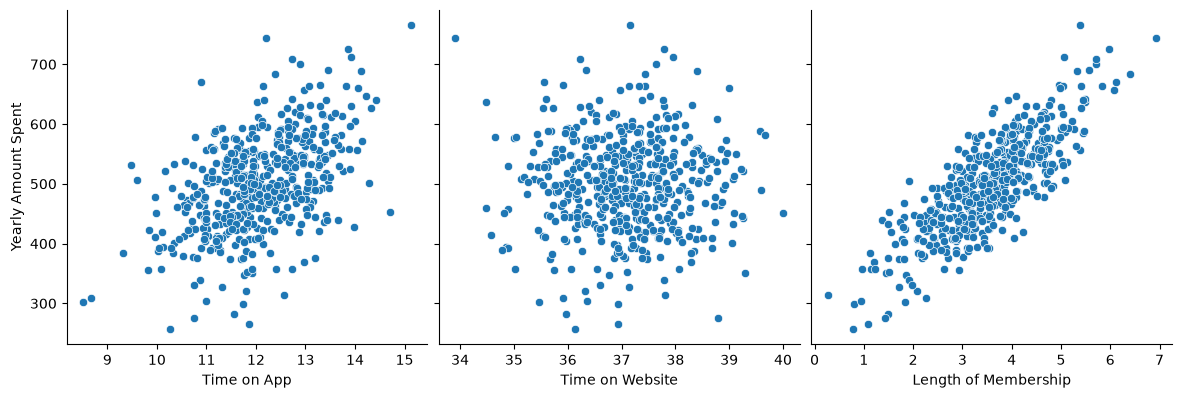

In [4]:
# Langkah 5: Visualisasi Data dengan Pairplot
# Menggunakan numeric columns untuk pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', height=4, aspect=1, kind='scatter')
plt.show()

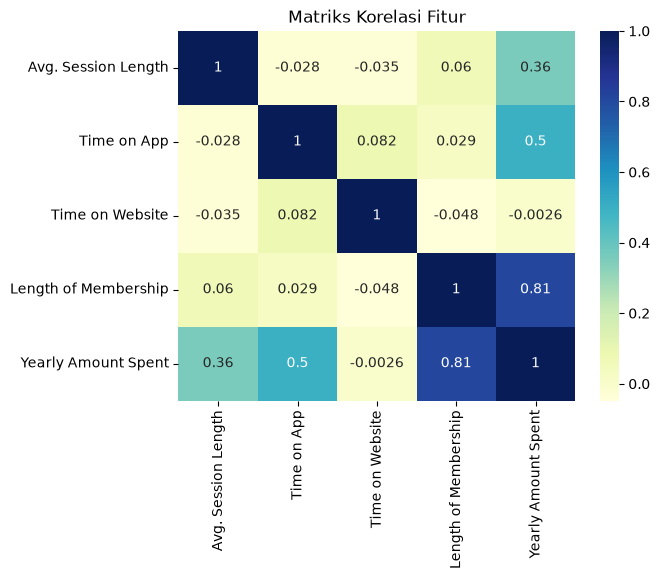

In [5]:
# Visualisasi korelasi dengan heatmap
numeric_data = data.select_dtypes(include=[np.number])
sns.heatmap(numeric_data.corr(), cmap="YlGnBu", annot=True)
plt.title("Matriks Korelasi Fitur")
plt.show()

In [6]:
# Langkah 6: Regresi Linier
# Membuat variabel bebas X dan Y berdasarkan analisis korelasi tertinggi (Length of Membership)
X = data['Length of Membership']
y = data['Yearly Amount Spent']

# Pembagian data latih dan data uji dengan proporsi 7:3
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

# Training model menggunakan OLS StatsModels
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()
print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Tue, 20 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         21:37:18   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

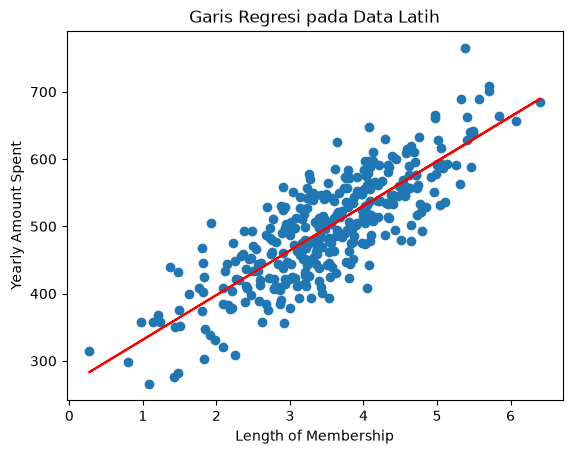

In [7]:
# Visualisasi garis regresi pada data latih
plt.scatter(X_train, y_train)
plt.plot(X_train, lr.params['const'] + lr.params['Length of Membership'] * X_train, 'r')
plt.title("Garis Regresi pada Data Latih")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.show()

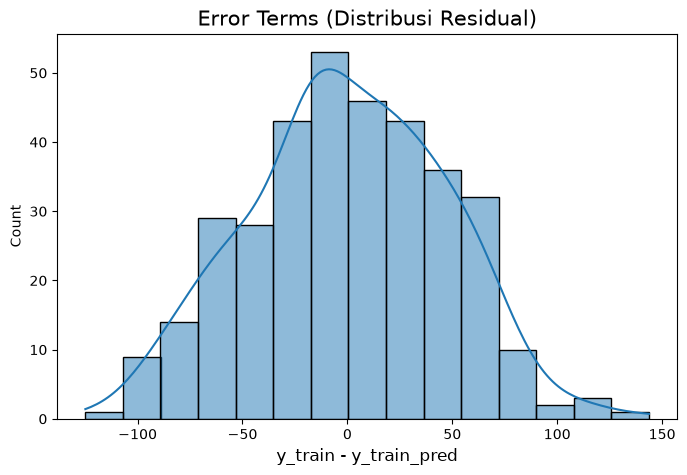

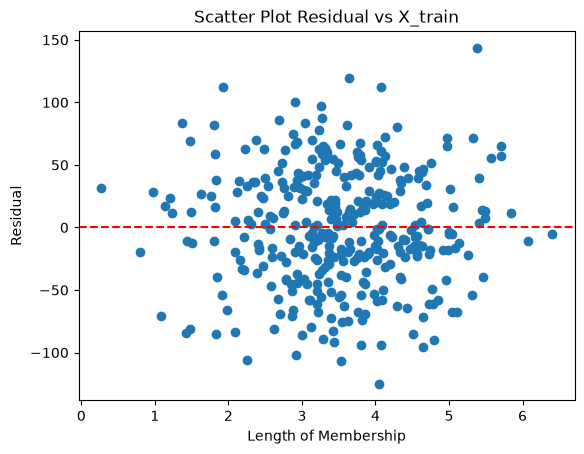

In [8]:
# Langkah 7: Analisis Residual
# Prediksi nilai y dari data latih
y_train_pred = lr.predict(X_train_sm)
res = (y_train - y_train_pred)

# Histogram residual (menggunakan sns.histplot dengan kde)
fig = plt.figure(figsize=(8, 5))
sns.histplot(res, bins=15, kde=True)
plt.title('Error Terms (Distribusi Residual)', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=12)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.axhline(0, color='red', linestyle='--')
plt.title('Scatter Plot Residual vs X_train')
plt.xlabel('Length of Membership')
plt.ylabel('Residual')
plt.show()

In [9]:
# Langkah 8: Prediksi pada Data Uji dan Evaluasi Model
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

# Hitung nilai R-squared
r_squared = r2_score(y_test, y_test_pred)
print(f"R-squared pada Data Uji: {r_squared:.4f}")

R-squared pada Data Uji: 0.6119


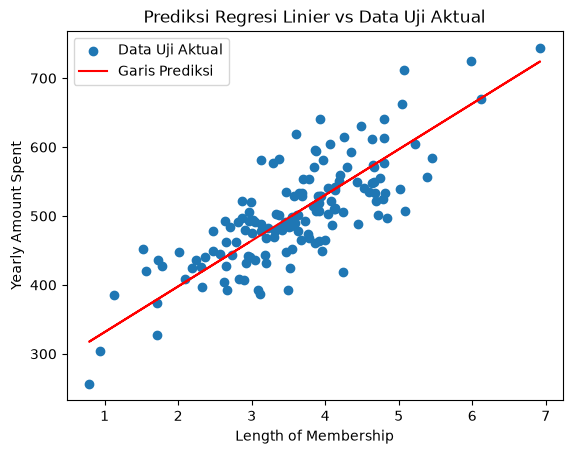

In [10]:
# Langkah 9: Visualisasi Hasil pada Data Uji
plt.scatter(X_test, y_test, label='Data Uji Aktual')
plt.plot(X_test, y_test_pred, 'r', label='Garis Prediksi')
plt.title("Prediksi Regresi Linier vs Data Uji Aktual")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.legend()
plt.show()